# Uber Fare Prediction
**Goal:** predict `fare_amount` for a trip *before* it ends, using historical Uber trips, and explain the findings to a manager.

**Team:** Janak · Darshan · Neetu · Tanya · Mohit

**Approach in one line:** clean → validate → explore → engineer booking-time features → compare models on the same 80/20 split (`random_state=42`) → tune with cross-validation on the training data only → evaluate and explain.

> Run this notebook from the project root or from `notebooks/`. It runs top to bottom on a fresh kernel.

In [1]:
# ---------- Setup ----------
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # one random_state everywhere -> repeatable results
sns.set_theme(style="whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "uber_trips_dataset_50k.csv"
if not DATA.exists():                  # fallback if the CSV sits in the project root
    DATA = ROOT / "uber_trips_dataset_50k.csv"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)

def save(name):
    """Save the current chart to reports/figures and show it."""
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150); plt.show()

print("Data file:", DATA)

Data file: C:\Users\tmanghnani\OneDrive - DXC Production\Desktop\Hackathon project\main_project\data\uber_trips_dataset_50k.csv


## Phase 1: Understand the data

In [2]:
df = pd.read_csv(DATA)
print("Shape (rows, columns):", df.shape)
print("\nColumn types:"); print(df.dtypes)
print("\nMissing values per column:"); print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum(), "| duplicate trip_id:", df["trip_id"].duplicated().sum())
df.head()

Shape (rows, columns): (50000, 14)

Column types:
trip_id             int64
driver_id           int64
rider_id            int64
city                  str
pickup_lat        float64
pickup_lng        float64
drop_lat          float64
drop_lng          float64
distance_km       float64
fare_amount       float64
status                str
payment_method        str
pickup_time           str
drop_time             str
dtype: object

Missing values per column:
trip_id           0
driver_id         0
rider_id          0
city              0
pickup_lat        0
pickup_lng        0
drop_lat          0
drop_lng          0
distance_km       0
fare_amount       0
status            0
payment_method    0
pickup_time       0
drop_time         0
dtype: int64

Duplicate rows: 0 | duplicate trip_id: 0


,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,01-01-2023 00:00,08:54.6
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,01-01-2023 00:01,26:17.4
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,01-01-2023 00:02,18:22.8
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,01-01-2023 00:03,22:49.8
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,01-01-2023 00:04,35:30.0


In [3]:
display(df.describe().round(2))
for col in ["city", "status", "payment_method"]:
    print(f"\n{col}:"); print(df[col].value_counts())

,trip_id,driver_id,rider_id,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,25000.50,5493.95,55040.99,39.00,-97.49,39.00,-97.49,7.01,15.98
std,14433.90,2601.41,25915.47,1.16,14.17,1.16,14.17,2.95,6.27
min,1.00,1000.00,10001.00,37.00,-122.00,36.95,-122.05,0.00,1.08
25%,12500.75,3232.75,32539.00,37.99,-109.82,38.00,-109.82,4.98,11.51
50%,25000.50,5497.00,55164.00,38.99,-97.46,38.99,-97.46,6.98,15.43
75%,37500.25,7746.00,77293.50,40.00,-85.19,40.00,-85.20,9.00,19.91
max,50000.00,9998.00,99998.00,41.00,-73.00,41.05,-72.96,19.41,50.67



city:
city
Boston           8454
San Francisco    8401
Chicago          8345
Los Angeles      8315
New York         8247
Seattle          8238
Name: count, dtype: int64

status:
status
Completed    42540
Cancelled     4984
No-Show       2476
Name: count, dtype: int64

payment_method:
payment_method
UPI       12549
Card      12533
Wallet    12505
Cash      12413
Name: count, dtype: int64


**What we see:** 50,000 rows, 14 columns, **no missing values and no duplicates**. Six cities and four payment methods appear in roughly equal numbers. 85% of trips are *Completed*.

In [4]:
# Convert the time columns to datetime
df["pickup_time"] = pd.to_datetime(df["pickup_time"], format="%d-%m-%Y %H:%M")
print("pickup_time range:", df["pickup_time"].min(), "->", df["pickup_time"].max(),
      f"({(df['pickup_time'].max() - df['pickup_time'].min()).days} days)")

# drop_time: try the same full timestamp format first
print("\ndrop_time samples:", df["drop_time"].head(5).tolist())
full = pd.to_datetime(df["drop_time"], format="%d-%m-%Y %H:%M", errors="coerce")
print("drop_time values that parse as a full date-time:", full.notna().sum(), "of", len(df))
# The values look like 'mm:ss.s' only - parse them as minutes:seconds to inspect them
mmss = df["drop_time"].astype(str).str.extract(r"^(\d+):(\d+(?:\.\d+)?)$").astype(float)
df["drop_time_mmss_min"] = mmss[0] + mmss[1] / 60
print(df["drop_time_mmss_min"].describe().round(2))

pickup_time range: 2023-01-01 00:00:00 -> 2023-02-04 17:19:00 (34 days)

drop_time samples: ['08:54.6', '26:17.4', '18:22.8', '22:49.8', '35:30.0']
drop_time values that parse as a full date-time: 0 of 50000
count    50000.00
mean        30.07
std         17.32
min          0.00
25%         15.06
50%         30.13
75%         45.14
max         59.99
Name: drop_time_mmss_min, dtype: float64


**Time columns:**
- `pickup_time` converts cleanly. The data covers **only about 35 days (Jan to Feb 2023)**.
- `drop_time` is **not a usable timestamp**: it only holds a `mm:ss.s` value (no date or hour), so we cannot build a trip duration from it. In any case `drop_time` is only known **after** the trip, so the golden rule already excludes it.

## Phase 2: Clean and validate

In [5]:
d_all = df.copy()
d_all["fare_per_km"] = d_all["fare_amount"] / d_all["distance_km"].replace(0, np.nan)
print("Zero or near-zero distance (<0.1 km):", (d_all["distance_km"] < 0.1).sum())
print("Long trips (>15 km):", (d_all["distance_km"] > 15).sum(), "| max distance:", d_all["distance_km"].max())
print("Very low fares (<$3):", (d_all["fare_amount"] < 3).sum(), "| very high fares (>$40):", (d_all["fare_amount"] > 40).sum())
print("\nFare per km:"); print(d_all["fare_per_km"].describe().round(2))
print("\nTrips with an unusual fare per km (> $10/km):", (d_all["fare_per_km"] > 10).sum())
d_all.nlargest(5, "fare_per_km")[["trip_id", "distance_km", "fare_amount", "fare_per_km", "status"]]

Zero or near-zero distance (<0.1 km): 72
Long trips (>15 km): 216 | max distance: 19.41
Very low fares (<$3): 265 | very high fares (>$40): 43

Fare per km:
count    49997.00
mean         2.61
std          4.53
min          1.29
25%          1.98
50%          2.36
75%          2.71
max        474.00
Name: fare_per_km, dtype: float64

Trips with an unusual fare per km (> $10/km): 301


,trip_id,distance_km,fare_amount,fare_per_km,status
29061,29062,0.01,4.74,474.0,Completed
26586,26587,0.01,3.52,352.0,Completed
5798,5799,0.01,3.05,305.0,Completed
42097,42098,0.01,2.98,298.0,Completed
48816,48817,0.01,2.34,234.0,Completed


**Suspicious values:** a few trips have almost zero distance, a few hundred have a very high fare per km (almost all are very short trips with a minimum-style fare), and fares above $40 are rare. These look like real edge cases (minimum fares, long trips), not data errors, so we **keep them** and flag them in the error analysis.

Correlation haversine_km vs distance_km: 0.002
Correlation haversine_km vs fare       : -0.0
Correlation distance_km  vs fare       : 0.871

Ratio distance_km / haversine_km:
count    50000.00
mean         2.48
std          3.57
min          0.00
25%          1.22
50%          1.83
75%          2.73
max        229.45
dtype: float64


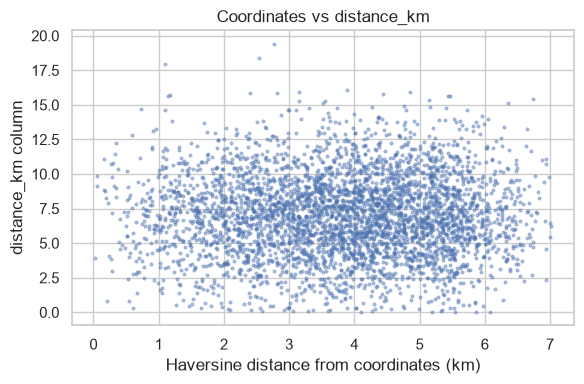

In [6]:
# ---- Coordinate check 1: does the distance from the coordinates match distance_km? ----
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(a))

d_all["haversine_km"] = haversine_km(d_all.pickup_lat, d_all.pickup_lng, d_all.drop_lat, d_all.drop_lng)
print("Correlation haversine_km vs distance_km:", round(d_all["haversine_km"].corr(d_all["distance_km"]), 3))
print("Correlation haversine_km vs fare       :", round(d_all["haversine_km"].corr(d_all["fare_amount"]), 3))
print("Correlation distance_km  vs fare       :", round(d_all["distance_km"].corr(d_all["fare_amount"]), 3))
print("\nRatio distance_km / haversine_km:"); print((d_all["distance_km"] / d_all["haversine_km"]).describe().round(2))

plt.figure(figsize=(6, 4))
s = d_all.sample(4000, random_state=RANDOM_STATE)
plt.scatter(s["haversine_km"], s["distance_km"], s=4, alpha=0.4)
plt.xlabel("Haversine distance from coordinates (km)"); plt.ylabel("distance_km column")
plt.title("Coordinates vs distance_km"); save("00_haversine_vs_distance")

Pickup coordinate range by city:


pickup_lat       pickup_lng      
                     min   max        min   max
city                                           
Boston              37.0  41.0     -122.0 -73.0
Chicago             37.0  41.0     -122.0 -73.0
Los Angeles         37.0  41.0     -122.0 -73.0
New York            37.0  41.0     -122.0 -73.0
San Francisco       37.0  41.0     -122.0 -73.0
Seattle             37.0  41.0     -122.0 -73.0

% of pickups within 50 km of their labelled city centre:
city
Boston           0.0
Chicago          0.0
Los Angeles      0.0
New York         0.3
San Francisco    0.0
Seattle          0.0
Name: km_from_city_centre, dtype: float64


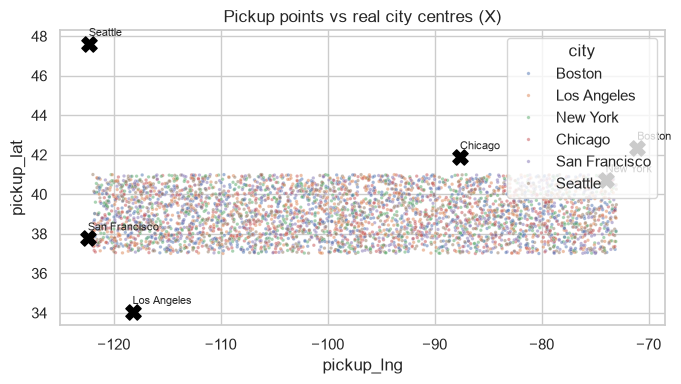

In [7]:
# ---- Coordinate check 2: do pickups fall inside the city they are labelled with? ----
CITY_CENTRE = {"New York": (40.71, -74.01), "San Francisco": (37.77, -122.42), "Los Angeles": (34.05, -118.24),
               "Chicago": (41.88, -87.63), "Boston": (42.36, -71.06), "Seattle": (47.61, -122.33)}
c = d_all["city"].map(CITY_CENTRE)
d_all["km_from_city_centre"] = haversine_km(d_all.pickup_lat, d_all.pickup_lng,
                                            c.str[0], c.str[1])
print("Pickup coordinate range by city:")
display(d_all.groupby("city")[["pickup_lat", "pickup_lng"]].agg(["min", "max"]).round(1))
inside = (d_all["km_from_city_centre"] < 50).groupby(d_all["city"]).mean().mul(100).round(1)
print("% of pickups within 50 km of their labelled city centre:"); print(inside)

plt.figure(figsize=(7, 4))
sns.scatterplot(data=s, x="pickup_lng", y="pickup_lat", hue="city", s=6, alpha=0.5)
for name, (la, lo) in CITY_CENTRE.items():
    plt.scatter(lo, la, marker="X", s=120, color="black"); plt.text(lo, la + 0.4, name, fontsize=8)
plt.title("Pickup points vs real city centres (X)"); save("00b_coordinates_vs_cities")

**Coordinate decision: we trust `distance_km`, not the coordinates.**
- The distance computed from the coordinates has **almost no relationship** with `distance_km` (correlation ≈ 0.00) and none with the fare.
- Every city has pickups spread over the **same rectangle** (latitude 37–41, longitude −122 to −73, roughly the whole USA). Almost no pickups are near their labelled city, and Los Angeles, Boston and Seattle lie completely outside that rectangle.
- `distance_km` correlates strongly with the fare (≈ 0.87) and behaves like a real trip distance.
- So the coordinates are **random / unreliable** and we do not use them as features.

In [8]:
# ---- Filter to Completed trips (rule of the hackathon) ----
before = len(df)
d = df[df["status"] == "Completed"].copy().reset_index(drop=True)
print(f"Rows before: {before:,} | Completed: {len(d):,} | removed: {before - len(d):,}")
print(df.loc[df["status"] != "Completed", "status"].value_counts())
print("\nMean fare by status:"); print(df.groupby("status")["fare_amount"].mean().round(2))

Rows before: 50,000 | Completed: 42,540 | removed: 7,460
status
Cancelled    4984
No-Show      2476
Name: count, dtype: int64

Mean fare by status:
status
Cancelled    15.97
Completed    15.98
No-Show      15.96
Name: fare_amount, dtype: float64


**Why only Completed trips:** we want the fare of a ride that actually happens. Cancelled and No-Show rows are not completed rides, so their `fare_amount` does not describe a real trip price (it may be a quote or a cancellation charge). We removed **7,460 rows** (4,984 Cancelled + 2,476 No-Show) and kept **42,540**.

### Cleaning decisions (summary)
| # | Decision | Reason |
|---|---|---|
| 1 | Keep all columns' rows: no missing values, no duplicates | Nothing to fill or drop |
| 2 | Keep only `status == Completed` (42,540 rows) | Only completed trips have a real trip fare; required by the rules |
| 3 | Keep near-zero and long trips | Real edge cases (minimum fares); dropping them would also change the official test set |
| 4 | Do **not** use coordinates | They do not match the city or `distance_km` |
| 5 | Use `distance_km` as the distance | Strong, consistent link with fare |
| 6 | Do **not** use `drop_time` | Broken format (`mm:ss.s` only) and known only after the trip |
| 7 | Drop `trip_id`, `driver_id`, `rider_id` | Identifiers carry no pricing information |

## Phase 3: Explore (EDA)
All charts use the 42,540 completed trips. Each chart is followed by one sentence: what we see and whether it matters for the model.

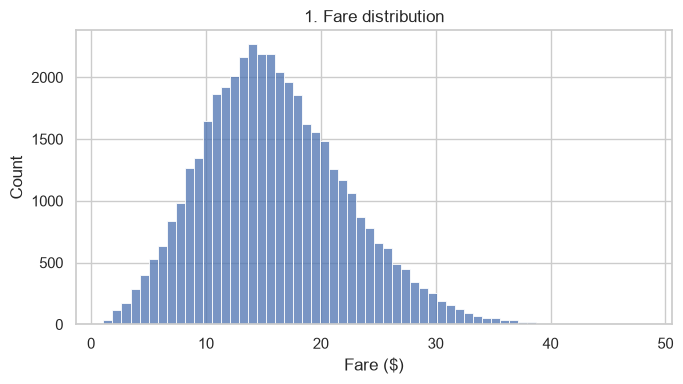

In [9]:
d["hour"] = d["pickup_time"].dt.hour
d["day_of_week"] = d["pickup_time"].dt.dayofweek          # 0 = Monday
d["day_name"] = d["pickup_time"].dt.day_name()
d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(7, 4)); sns.histplot(d["fare_amount"], bins=60)
plt.title("1. Fare distribution"); plt.xlabel("Fare ($)"); save("01_fare_distribution")

**1.** Fares centre around $15–16 with a slight right tail up to about $50; there are no negative or absurd fares, so no target transform is needed.

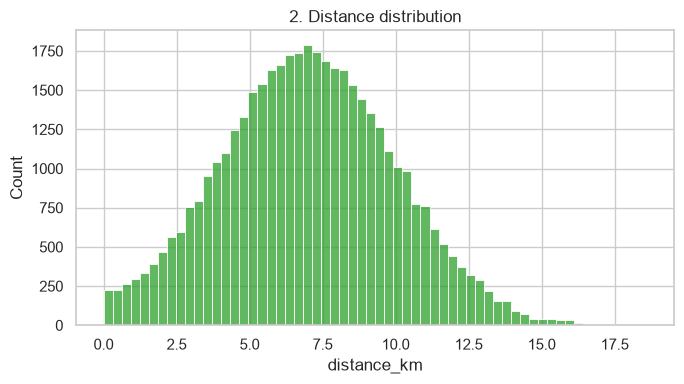

In [10]:
plt.figure(figsize=(7, 4)); sns.histplot(d["distance_km"], bins=60, color="tab:green")
plt.title("2. Distance distribution"); plt.xlabel("distance_km"); save("02_distance_distribution")

**2.** Most trips are 3–11 km (mean about 7 km, max about 19 km); very long trips are rare, so predictions for long trips will be less certain.

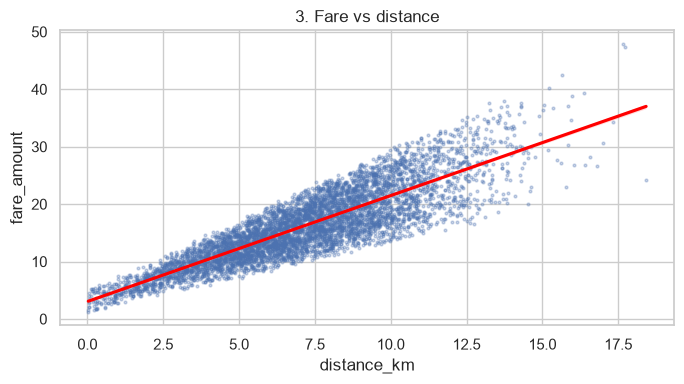

Correlation: 0.871


In [11]:
s = d.sample(6000, random_state=RANDOM_STATE)
plt.figure(figsize=(7, 4)); sns.regplot(data=s, x="distance_km", y="fare_amount",
                                        scatter_kws={"s": 4, "alpha": 0.3}, line_kws={"color": "red"})
plt.title("3. Fare vs distance"); save("03_fare_vs_distance")
print("Correlation:", round(d["distance_km"].corr(d["fare_amount"]), 3))

**3.** Fare rises in an almost straight line with distance, and the spread around the line is the same size at every distance band, so distance is the key feature and a linear model is a strong candidate.

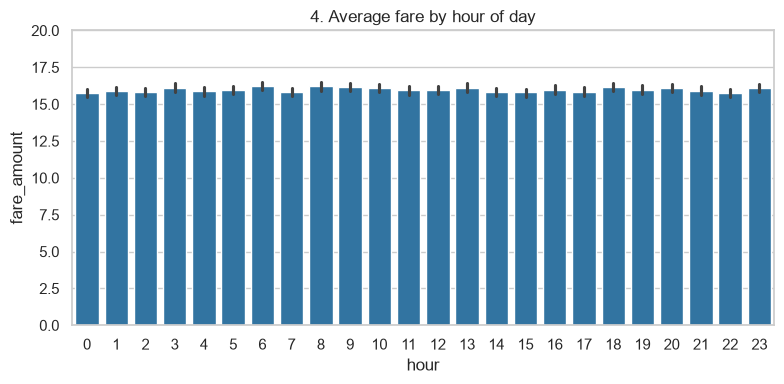

min    15.77
max    16.21
Name: fare_amount, dtype: float64


In [12]:
plt.figure(figsize=(8, 4)); sns.barplot(data=d, x="hour", y="fare_amount", errorbar=("ci", 95), color="tab:blue")
plt.title("4. Average fare by hour of day"); plt.ylim(0, 20); save("04_fare_by_hour")
print(d.groupby("hour")["fare_amount"].mean().agg(["min", "max"]).round(2))

**4.** The average fare is flat across the day (all hours within about ±$0.25 of $16, overlapping confidence bars), so hour of day adds almost nothing.

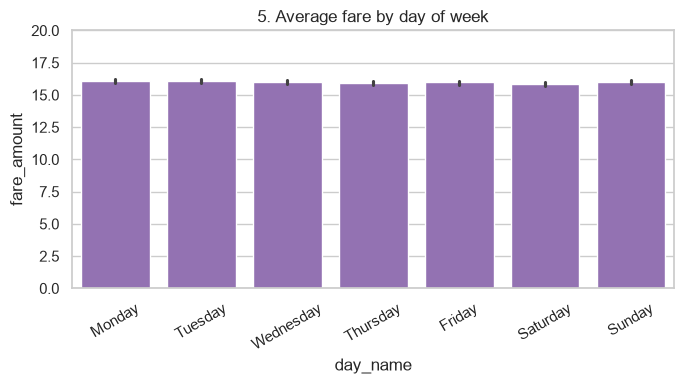

In [13]:
plt.figure(figsize=(7, 4)); sns.barplot(data=d, x="day_name", y="fare_amount", order=DAY_ORDER, color="tab:purple")
plt.title("5. Average fare by day of week"); plt.xticks(rotation=30); plt.ylim(0, 20); save("05_fare_by_day")

**5.** Fares are the same on every weekday and at weekends, so day of week and the weekend flag should not move the prediction.

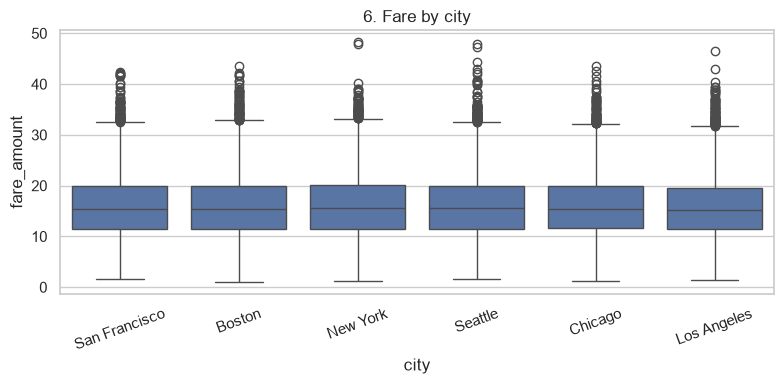

city
Boston           16.02
Chicago          15.91
Los Angeles      15.74
New York         16.09
San Francisco    16.02
Seattle          16.10
Name: fare_amount, dtype: float64


In [14]:
plt.figure(figsize=(8, 4)); sns.boxplot(data=d, x="city", y="fare_amount")
plt.title("6. Fare by city"); plt.xticks(rotation=20); save("06_fare_by_city")
print(d.groupby("city")["fare_amount"].mean().round(2))

**6.** All six cities have the same fare distribution (means within about $0.40), so city does not change the price in this data.

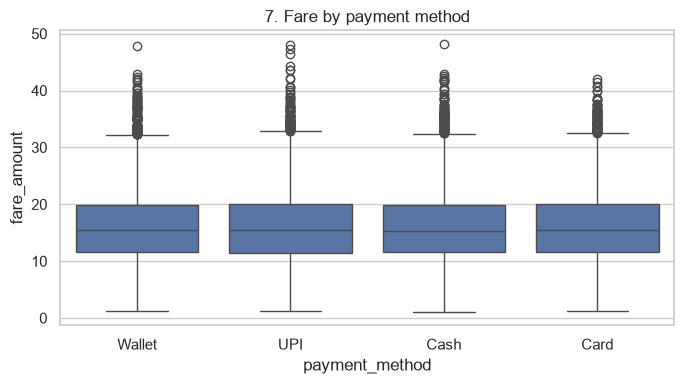

payment_method
Card      16.03
Cash      15.95
UPI       15.95
Wallet    15.97
Name: fare_amount, dtype: float64


In [15]:
plt.figure(figsize=(7, 4)); sns.boxplot(data=d, x="payment_method", y="fare_amount")
plt.title("7. Fare by payment method"); save("07_fare_by_payment")
print(d.groupby("payment_method")["fare_amount"].mean().round(2))

**7.** Card, Cash, UPI and Wallet give the same fares, so payment method does not matter for the price.

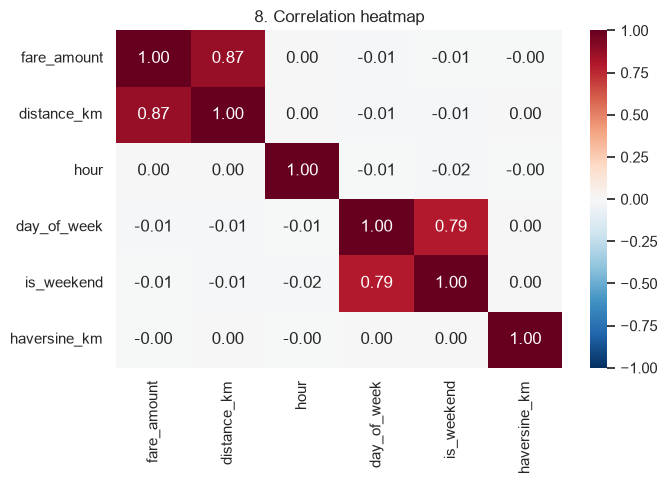

In [16]:
num = d[["fare_amount", "distance_km", "hour", "day_of_week", "is_weekend"]].copy()
num["haversine_km"] = haversine_km(d.pickup_lat, d.pickup_lng, d.drop_lat, d.drop_lng)
plt.figure(figsize=(7, 5)); sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("8. Correlation heatmap"); save("08_correlation_heatmap")

**8.** Only `distance_km` is strongly correlated with fare; time features and the coordinate distance are near zero, confirming distance is the single main driver.

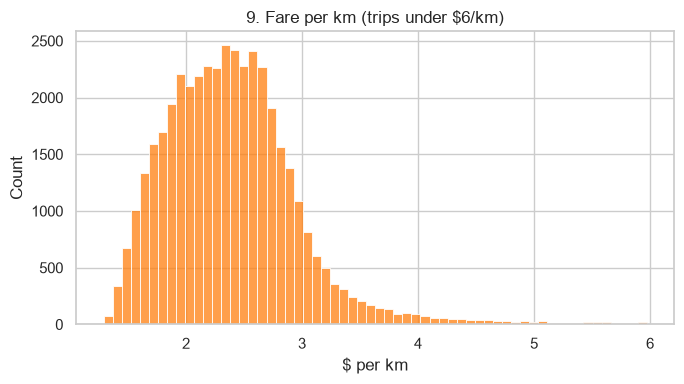

Median fare per km: 2.35


In [17]:
fpk = (d["fare_amount"] / d["distance_km"]).replace(np.inf, np.nan)
plt.figure(figsize=(7, 4)); sns.histplot(fpk[fpk < 6], bins=60, color="tab:orange")
plt.title("9. Fare per km (trips under $6/km)"); plt.xlabel("$ per km"); save("09_fare_per_km")
print("Median fare per km:", round(fpk.median(), 2))

**9.** Most trips cost about $2–3 per km; the long tail comes from very short trips where a fixed base charge dominates, which a model with an intercept captures.

## Phase 4: Feature engineering
**Golden rule:** a feature must be known at **booking time**.

| Feature | Kept? | Why allowed (golden rule) / why it should help |
|---|---|---|
| `distance_km` | ✅ | The route distance is estimated when the trip is booked; it is the main driver of fare |
| `hour` | ✅ | Booking time is known; could capture time-of-day pricing |
| `day_of_week` | ✅ | Known at booking; could capture weekday patterns |
| `is_weekend` | ✅ | Known at booking; simple weekend effect |
| `city` (one-hot) | ✅ | Known at booking; captures city price levels if any |
| `payment_method` (one-hot) | ✅ | Chosen at booking; tests whether payment changes price |
| `month`, `year` | ❌ | Only ~35 days of data (Jan–Feb 2023): one year and two months, so they cannot generalise |
| coordinates / Haversine | ❌ | Do not match the city or `distance_km` (Phase 2) |
| `drop_time`, trip duration | ❌ | Only known **after** the trip (leakage) and broken format |
| `status` | ❌ | Used as a filter; a Completed status is only known after the trip |
| fare per km | ❌ | Built from the fare itself (leakage) |
| IDs | ❌ | No pricing information |

`city` and `payment_method` are text, so they are **one-hot encoded** (one 0/1 column per value) inside the model pipeline. The weak features are kept on purpose so the models can prove whether they help.

In [18]:
NUM = ["distance_km", "hour", "day_of_week", "is_weekend"]
CAT = ["city", "payment_method"]
FEATURES = NUM + CAT

def preprocess():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT)], remainder="passthrough")

X = d[FEATURES]
y = d["fare_amount"]
print("X shape:", X.shape)
X.head()

X shape: (42540, 6)


,distance_km,hour,day_of_week,is_weekend,city,payment_method
0,2.97,0,6,1,San Francisco,Wallet
1,8.43,0,6,1,Boston,UPI
2,5.46,0,6,1,San Francisco,Cash
3,6.61,0,6,1,New York,Wallet
4,10.50,0,6,1,Seattle,Wallet


## Phase 5: Modeling
Same split for every model: **80/20, `random_state=42`**, on the 42,540 completed trips (identical to the organisers' baseline split).
Tuning and model selection use **5-fold cross-validation on the training set only**; the test set is used once, at the end.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make(model, cols="all"):
    if cols == "distance":
        return Pipeline([("select", ColumnTransformer([("d", "passthrough", ["distance_km"])])), ("model", model)])
    return Pipeline([("prep", preprocess()), ("model", model)])

candidates = {
    "Predict the average": make(DummyRegressor(strategy="mean"), "distance"),
    "Baseline: Linear Regression (distance only)": make(LinearRegression(), "distance"),
    "Linear Regression (all features)": make(LinearRegression()),
    "Random Forest": make(RandomForestRegressor(n_estimators=300, min_samples_leaf=20, n_jobs=-1,
                                                random_state=RANDOM_STATE)),
    "Gradient Boosting": make(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}
try:
    from xgboost import XGBRegressor
    candidates["XGBoost"] = make(XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8,
                                              colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1))
except ImportError:
    print("xgboost not installed - skipping (optional)")

Train: (34032, 6) | Test: (8508, 6)


In [20]:
# ---- Tune Gradient Boosting with RandomizedSearchCV (training data only) ----
search = RandomizedSearchCV(
    make(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_distributions={
        "model__n_estimators": [100, 200, 300],
        "model__learning_rate": [0.02, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_samples_leaf": [20, 50, 100],
        "model__subsample": [0.7, 0.85, 1.0],
    },
    n_iter=12, cv=3, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time(); search.fit(X_train, y_train)
print(f"Tuning took {time.time() - t0:.0f}s")
print("Best parameters:", search.best_params_)
print("Best CV RMSE:", round(-search.best_score_, 3))
candidates["Gradient Boosting (tuned)"] = search.best_estimator_

Tuning took 84s
Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_samples_leaf': 20, 'model__max_depth': 2, 'model__learning_rate': 0.02}
Best CV RMSE: 3.09


In [21]:
# ---- Fit every model, score it with CV on train and once on the test set ----
rows, fitted = [], {}
for name, model in candidates.items():
    t0 = time.time()
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error", n_jobs=-1).mean()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": mean_squared_error(y_test, pred) ** 0.5,
                 "R2": r2_score(y_test, pred),
                 "Train_R2": r2_score(y_train, model.predict(X_train)),
                 "CV_RMSE": cv_rmse,
                 "Seconds": time.time() - t0})
    fitted[name] = model

results = pd.DataFrame(rows).set_index("Model")
base = results.loc["Baseline: Linear Regression (distance only)"]
results["MAE_vs_baseline"] = results["MAE"] - base["MAE"]
results.round(3)

,MAE,RMSE,R2,Train_R2,CV_RMSE,Seconds,MAE_vs_baseline
Model,,,,,,,
Predict the average,4.956,6.208,-0.000,0.000,6.297,0.053,2.465
Baseline: Linear Regression (distance only),2.491,3.103,0.750,0.760,3.084,0.054,0.000
Linear Regression (all features),2.491,3.103,0.750,0.760,3.084,0.145,0.000
Random Forest,2.514,3.142,0.744,0.790,3.119,13.428,0.023
Gradient Boosting,2.493,3.113,0.748,0.765,3.093,6.563,0.002
XGBoost,2.504,3.134,0.745,0.772,3.118,6.696,0.013
Gradient Boosting (tuned),2.493,3.106,0.750,0.762,3.091,11.324,0.002


**Reading the table:** lower MAE/RMSE and higher R² are better. `Train_R2` much higher than `R2` would mean overfitting. `CV_RMSE` is the cross-validated error on the training set; we use it (not the test set) to **choose** the final model.

In [22]:
# Choose the final model by cross-validation (never by the test set).
# If a complex model is not clearly better (less than 1% lower CV RMSE) than the baseline,
# we prefer the simpler, explainable linear model.
ranked = results.drop(index="Predict the average").sort_values("CV_RMSE")
best_cv = ranked.index[0]
gain = (base["CV_RMSE"] - ranked.loc[best_cv, "CV_RMSE"]) / base["CV_RMSE"]
final_name = best_cv if gain >= 0.01 else "Baseline: Linear Regression (distance only)"
final = fitted[final_name]
print(f"Lowest CV RMSE: {best_cv} ({gain:.2%} better than the baseline on CV)")
print("Final model:", final_name)

Lowest CV RMSE: Baseline: Linear Regression (distance only) (0.00% better than the baseline on CV)
Final model: Baseline: Linear Regression (distance only)


## Phase 6: Evaluate and explain

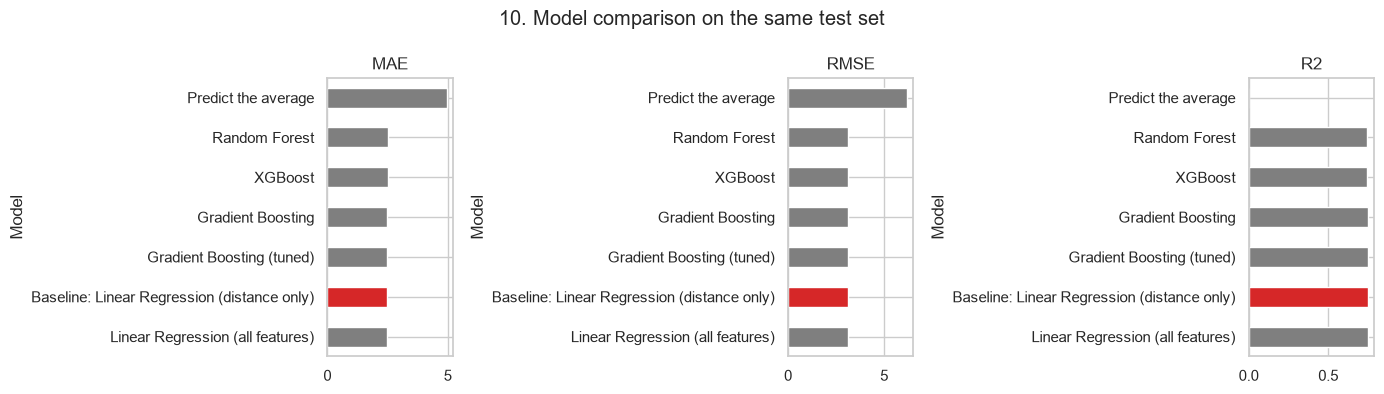

,MAE,RMSE,R2
Model,,,
Linear Regression (all features),2.491,3.103,0.750
Baseline: Linear Regression (distance only),2.491,3.103,0.750
Gradient Boosting (tuned),2.493,3.106,0.750
Gradient Boosting,2.493,3.113,0.748
XGBoost,2.504,3.134,0.745
Random Forest,2.514,3.142,0.744
Predict the average,4.956,6.208,-0.000


In [23]:
order = results.sort_values("RMSE")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, m in zip(ax, ["MAE", "RMSE", "R2"]):
    order[m].plot(kind="barh", ax=a, color=["tab:red" if i == final_name else "tab:gray" for i in order.index])
    a.set_title(m)
plt.suptitle("10. Model comparison on the same test set"); save("10_model_comparison")
order[["MAE", "RMSE", "R2"]].round(3)

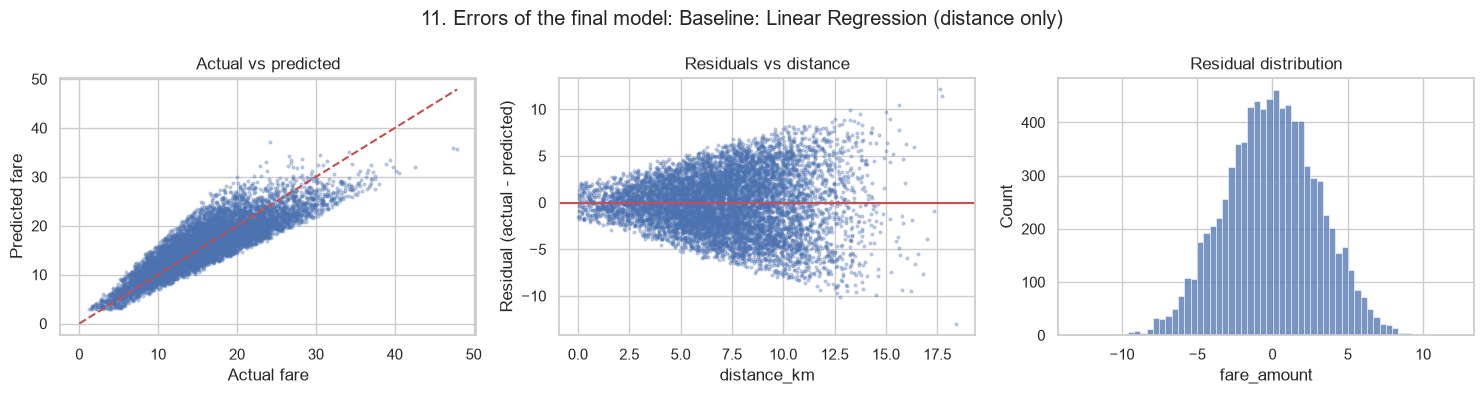

Mean absolute error by distance band:


,mean,count
band,,
"(0, 3]",1.08,757
"(3, 6]",1.78,2354
"(6, 9]",2.60,3276
"(9, 12]",3.44,1707
"(12, 20]",4.34,414


Largest errors:


,distance_km,city,actual,predicted,error
19487,18.42,Boston,24.22,37.18,-12.96
21989,17.66,Seattle,47.90,35.77,12.13
33241,17.72,Seattle,47.35,35.88,11.47
28594,15.66,Chicago,42.52,32.06,10.46
24275,12.76,Chicago,16.58,26.67,-10.09
11843,13.25,New York,37.52,27.58,9.94
10075,14.53,Los Angeles,20.02,29.96,-9.94
18195,12.60,Los Angeles,16.68,26.37,-9.69


In [24]:
pred = final.predict(X_test)
res = y_test - pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_test, pred, s=4, alpha=0.3); lim = [0, y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual fare"); ax[0].set_ylabel("Predicted fare"); ax[0].set_title("Actual vs predicted")
ax[1].scatter(X_test["distance_km"], res, s=4, alpha=0.3); ax[1].axhline(0, color="r")
ax[1].set_xlabel("distance_km"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residuals vs distance")
sns.histplot(res, bins=60, ax=ax[2]); ax[2].set_title("Residual distribution")
plt.suptitle(f"11. Errors of the final model: {final_name}"); save("11_actual_vs_predicted_residuals")

bands = pd.cut(X_test["distance_km"], [0, 3, 6, 9, 12, 20])
err = pd.DataFrame({"band": bands, "abs_err": res.abs()})
print("Mean absolute error by distance band:")
display(err.groupby("band", observed=True)["abs_err"].agg(["mean", "count"]).round(2))
print("Largest errors:")
big = X_test.assign(actual=y_test, predicted=pred, error=res).reindex(res.abs().sort_values(ascending=False).index)
display(big.head(8)[["distance_km", "city", "actual", "predicted", "error"]].round(2))

**Where are the biggest errors?** Errors grow with distance: short trips are predicted within about $1, long trips (12 km+) are off by roughly $4 on average. The largest single errors are trips whose fare is far from the usual price for their distance (for example a short trip with a very high fare). Nothing in the booking-time data explains them, so they are noise from the model's point of view.

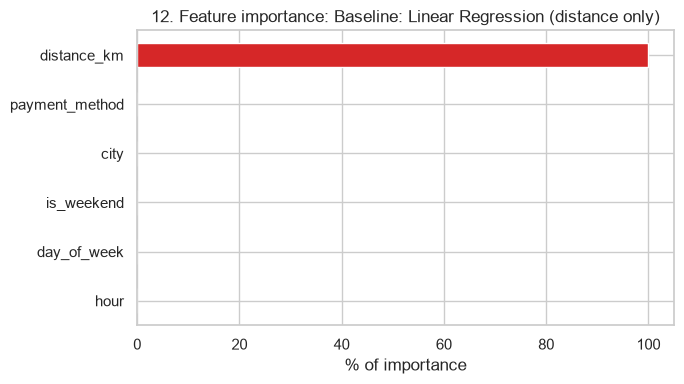

Baseline linear model: fare = $2.97 + $1.86 x distance_km


distance_km       100.0
hour                0.0
day_of_week         0.0
is_weekend          0.0
city                0.0
payment_method      0.0
dtype: float64

In [25]:
# Feature importance of the final model (permutation importance on the test set)
pi = permutation_importance(final, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
                            scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).clip(lower=0)
imp_pct = (imp / imp.sum() * 100).sort_values()
plt.figure(figsize=(7, 4)); imp_pct.plot(kind="barh", color="tab:red")
plt.title(f"12. Feature importance: {final_name}"); plt.xlabel("% of importance"); save("12_feature_importance")

lr = fitted["Baseline: Linear Regression (distance only)"].named_steps["model"]
RATE, BASE_FARE = float(lr.coef_[0]), float(lr.intercept_)
print(f"Baseline linear model: fare = ${BASE_FARE:.2f} + ${RATE:.2f} x distance_km")
imp_pct.sort_values(ascending=False).round(1)

In [28]:
# ---- Save the final model (bonus app uses it) and the results for the slides/README ----
best_row = results.loc[final_name]
bundle = {
    "model": final, "model_name": final_name, "features": FEATURES,
    "metrics": {k: float(best_row[k]) for k in ["MAE", "RMSE", "R2"]},
    "all_metrics": {n: {k: round(float(r[k]), 3) for k in ["MAE", "RMSE", "R2", "Train_R2", "CV_RMSE"]}
                    for n, r in results.iterrows()},
    "rows": int(len(d)), "importance": imp_pct.round(1).to_dict(),
    "rate_per_km": RATE, "base_fare": BASE_FARE, "currency": "USD",
}
joblib.dump(bundle, MODELS / "uber_fare_model.pkl")
(ROOT / "reports").mkdir(exist_ok=True)
results.round(4).to_csv(ROOT / "reports" / "results.csv")
json.dump({"final_model": final_name, "rate_per_km": round(RATE, 3), "base_fare": round(BASE_FARE, 3),
           "rows_completed": int(len(d)), "rows_removed": int(len(df) - len(d)),
           "results": results.round(4).reset_index().to_dict(orient="records"),
           "importance": imp_pct.sort_values(ascending=False).round(1).to_dict(),
           "best_params": search.best_params_},
          open(ROOT / "reports" / "results.json", "w"), indent=2, default=str)
print("Saved models/uber_fare_model.pkl, reports/results.csv, reports/results.json")

Saved models/uber_fare_model.pkl, reports/results.csv, reports/results.json


## Business questions

In [27]:
def spread(col):
    m = d.groupby(col)["fare_amount"].mean()
    return f"${m.min():.2f} to ${m.max():.2f} (spread ${m.max() - m.min():.2f})"

top = imp_pct.sort_values(ascending=False)
best_test = results.drop(index=["Predict the average"]).sort_values("RMSE").iloc[0]
best_test_name = results.drop(index=["Predict the average"]).sort_values("RMSE").index[0]
print("1. Main factors:", ", ".join(f"{k} {v:.1f}%" for k, v in top.head(3).items()))
print(f"2. Rate: about ${RATE:.2f} per km plus a base of about ${BASE_FARE:.2f} "
      f"(a 10 km trip is about ${BASE_FARE + 10 * RATE:.2f}).")
print("3. Average fare by hour:", spread("hour"), "| by day:", spread("day_of_week"),
      "| by city:", spread("city"), "| by payment:", spread("payment_method"))
print(f"4. Best on the test set: {best_test_name} with RMSE {best_test['RMSE']:.3f} vs baseline {base['RMSE']:.3f} "
      f"(MAE {best_test['MAE']:.3f} vs {base['MAE']:.3f}).")
print(f"   Final model chosen by cross-validation: {final_name}.")
print(f"5. On average the final model is off by ${results.loc[final_name, 'MAE']:.2f} per trip "
      f"(R2 {results.loc[final_name, 'R2']:.2f}).")

1. Main factors: distance_km 100.0%, hour 0.0%, day_of_week 0.0%
2. Rate: about $1.86 per km plus a base of about $2.97 (a 10 km trip is about $21.54).
3. Average fare by hour: $15.77 to $16.21 (spread $0.44) | by day: $15.86 to $16.11 (spread $0.26) | by city: $15.74 to $16.10 (spread $0.36) | by payment: $15.95 to $16.03 (spread $0.08)
4. Best on the test set: Linear Regression (all features) with RMSE 3.103 vs baseline 3.103 (MAE 2.491 vs 2.491).
   Final model chosen by cross-validation: Baseline: Linear Regression (distance only).
5. On average the final model is off by $2.49 per trip (R2 0.75).


1. **What most influences the fare?** Trip distance, by far (see the importance chart and heatmap). Everything else is close to zero.
2. **Distance effect:** roughly a base charge plus a fixed rate per km (printed above; about $3 + $1.86/km).
3. **Hour, day, city, payment:** no meaningful effect. Group averages differ by only a few tens of cents, smaller than the normal trip-to-trip variation.
4. **Best model vs baseline:** the more complex models land **at the baseline level, not clearly above it**. The data's fare is essentially *distance × rate + random noise*, so once distance is used there is no extra signal for any model to learn. We report this honestly instead of claiming a gain.
5. **Accuracy in dollars:** on average the estimate is about **$2.50 away** from the real fare (MAE); about $1 on short trips and about $4 on long ones.
6. **New trip?** Yes, for a normal trip of about 0.5–15 km in one of these cities. **Do not trust it** for trips longer than ~15 km (few examples), for distances estimated from these coordinates, for other cities, or during events or surge pricing the data does not record.
7. **One extra piece of data:** the **surge multiplier / live demand at booking time** (or real traffic-based expected duration). The spread of fares at the same distance is the unexplained part, and surge or traffic is the most likely cause.

## Limits and next steps
- About 25% of fare variation cannot be explained by booking-time data; the remaining error is noise to the model.
- Only 35 days of data, so seasonal effects cannot be learned.
- Coordinates are unreliable; with correct GPS we could compute real route distances and city zones.
- Next: collect surge/demand and traffic features, re-validate coordinates, retrain monthly, and monitor error over time.